In [1]:
import zipfile
import os

zip_path = "/content/archive (3).zip"
extract_path = "/content/Logistics_Dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(file)

Dataset extracted successfully!
olist_order_payments_dataset.csv
olist_orders_dataset.csv
olist_geolocation_dataset.csv
product_category_name_translation.csv
olist_products_dataset.csv
olist_customers_dataset.csv
olist_order_items_dataset.csv
olist_sellers_dataset.csv
olist_order_reviews_dataset.csv


In [2]:
import pandas as pd
import numpy as np

file_path = "/content/Logistics_Dataset/olist_orders_dataset.csv"

df = pd.read_csv(file_path)

print("Dataset Imported Successfully!")
print("\nFirst 5 Rows:")
display(df.head())

Dataset Imported Successfully!

First 5 Rows:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape:
(99441, 8)

Column Names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Missing

In [4]:

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')

print("Date Format Conversion Completed!")

print("\nUpdated Data Types:")
print(df[date_columns].dtypes)

print("\nUpdated Dataset Information:")
df.info()

Date Format Conversion Completed!

Updated Data Types:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Updated Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delive

In [5]:

print("Order Status Distribution:")

print(df['order_status'].value_counts())

print("\nMissing Values by Order Status:")

display(
    df.groupby('order_status')[
        ['order_approved_at',
         'order_delivered_carrier_date',
         'order_delivered_customer_date']
    ].apply(lambda x: x.isnull().sum())
)

Order Status Distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Missing Values by Order Status:


,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


In [6]:

missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_report = pd.DataFrame({
    'Missing Values': missing_count,
    'Missing Percentage': missing_percentage.round(2)
})

print("Missing Values Analysis Report:")
display(missing_report)

Missing Values Analysis Report:


,Missing Values,Missing Percentage
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00


In [7]:

delivered_orders = df[df['order_status'] == 'delivered']

print("Total Delivered Orders:", len(delivered_orders))

print("Missing Approval Dates:",
      delivered_orders['order_approved_at'].isnull().sum())

print("Missing Carrier Dates:",
      delivered_orders['order_delivered_carrier_date'].isnull().sum())

print("Missing Customer Delivery Dates:",
      delivered_orders['order_delivered_customer_date'].isnull().sum())

Total Delivered Orders: 96478
Missing Approval Dates: 14
Missing Carrier Dates: 2
Missing Customer Delivery Dates: 8


In [8]:

missing_delivered = delivered_orders[
    delivered_orders[
        ['order_approved_at',
         'order_delivered_carrier_date',
         'order_delivered_customer_date']
    ].isnull().any(axis=1)
]

print("Total Records with Missing Dates:",
      len(missing_delivered))

display(missing_delivered.head(20))

Total Records with Missing Dates: 23


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
5323,e04abd8149ef81b95221e88f6ed9ab6a,2127dc6603ac33544953ef05ec155771,delivered,2017-02-18 14:40:00,NaT,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17
16567,8a9adc69528e1001fc68dd0aaebbb54a,4c1ccc74e00993733742a3c786dc3c1f,delivered,2017-02-18 12:45:31,NaT,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21
19031,7013bcfc1c97fe719a7b5e05e61c12db,2941af76d38100e0f8740a374f1a5dc3,delivered,2017-02-18 13:29:47,NaT,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
22663,5cf925b116421afa85ee25e99b4c34fb,29c35fc91fc13fb5073c8f30505d860d,delivered,2017-02-18 16:48:35,NaT,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31
23156,12a95a3c06dbaec84bcfb0e2da5d228a,1e101e0daffaddce8159d25a8e53f2b2,delivered,2017-02-17 13:05:55,NaT,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20
26800,c1d4211b3dae76144deccd6c74144a88,684cb238dc5b5d6366244e0e0776b450,delivered,2017-01-19 12:48:08,NaT,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01
38290,d69e5d356402adc8cf17e08b5033acfb,68d081753ad4fe22fc4d410a9eb1ca01,delivered,2017-02-19 01:28:47,NaT,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27
39334,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:19,NaT,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22


In [9]:

print("Total Duplicate Rows:", df.duplicated().sum())

print("Duplicate Order IDs:", df['order_id'].duplicated().sum())

print("Unique Order IDs:", df['order_id'].nunique())


Total Duplicate Rows: 0
Duplicate Order IDs: 0
Unique Order IDs: 99441


In [10]:

invalid_approval = df[
    df['order_approved_at'] < df['order_purchase_timestamp']
]

invalid_delivery = df[
    df['order_delivered_customer_date'] <
    df['order_delivered_carrier_date']
]

print("Invalid Approval Date Records:", len(invalid_approval))

print("Invalid Delivery Date Records:", len(invalid_delivery))

Invalid Approval Date Records: 0
Invalid Delivery Date Records: 23


In [11]:

invalid_records = df[
    df['order_delivered_customer_date'] <
    df['order_delivered_carrier_date']
]

print("Total Invalid Records:", len(invalid_records))

display(
    invalid_records[
        ['order_id',
         'order_status',
         'order_delivered_carrier_date',
         'order_delivered_customer_date']
    ]
)

Total Invalid Records: 23


,order_id,order_status,order_delivered_carrier_date,order_delivered_customer_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,delivered,2017-07-28 16:57:58,2017-07-25 19:32:56
9553,383aa8b2724fe452d9ccd9934a8c628b,delivered,2017-07-07 17:22:41,2017-07-06 14:27:51
13487,cb1134f9010d242e9515ad1c78ec0c39,delivered,2017-07-20 19:22:02,2017-07-19 14:13:28
14474,dceb62e8fa94b46006c9554fed743df0,delivered,2017-08-01 18:23:30,2017-07-26 18:09:10
19268,5f9d46795c3126674e52becb3a1a517f,delivered,2017-07-20 23:03:42,2017-07-20 18:52:41
21338,8c78d01de3a9009e23d6877a7cc9be20,delivered,2016-10-26 11:41:53,2016-10-25 17:51:46
22520,b27af682321527a6349f1761eb3f360c,delivered,2017-06-27 14:51:54,2017-06-26 15:45:35
25393,1cc3ae63caffff2d6c3ee3e78e074acf,delivered,2017-08-10 18:28:56,2017-08-10 18:05:38
25646,e37f11cae9985ca58f0b56f268720537,delivered,2017-08-01 18:17:47,2017-07-31 17:49:56
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,delivered,2017-08-09 18:18:43,2017-08-01 21:13:01


In [12]:

print("Total Duplicate Rows:", df.duplicated().sum())

print("Duplicate Order IDs:",
      df['order_id'].duplicated().sum())

print("Unique Order IDs:",
      df['order_id'].nunique())

Total Duplicate Rows: 0
Duplicate Order IDs: 0
Unique Order IDs: 99441


In [13]:

invalid_records = df[
    df['order_delivered_customer_date'] <
    df['order_delivered_carrier_date']
]

display(invalid_records)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,5f50465da00b7fed5dd1239f4ecf6e2c,delivered,2017-07-20 11:20:52,2017-07-21 06:43:14,2017-07-28 16:57:58,2017-07-25 19:32:56,2017-08-14
9553,383aa8b2724fe452d9ccd9934a8c628b,b1cb2f9d7a19480f3749e248db14d58f,delivered,2017-07-02 20:58:43,2017-07-02 21:10:20,2017-07-07 17:22:41,2017-07-06 14:27:51,2017-07-21
13487,cb1134f9010d242e9515ad1c78ec0c39,2fd33ac77677bd214b1882868317eeed,delivered,2017-07-16 12:35:34,2017-07-18 06:03:50,2017-07-20 19:22:02,2017-07-19 14:13:28,2017-08-08
14474,dceb62e8fa94b46006c9554fed743df0,2721900eb4e0f1cc2c836dd7bc1b1e11,delivered,2017-07-20 20:58:05,2017-07-22 11:45:11,2017-08-01 18:23:30,2017-07-26 18:09:10,2017-08-11
19268,5f9d46795c3126674e52becb3a1a517f,79287bcaafdde5c793b996fc40bb7d9f,delivered,2017-07-18 11:48:20,2017-07-18 12:03:29,2017-07-20 23:03:42,2017-07-20 18:52:41,2017-07-31
21338,8c78d01de3a9009e23d6877a7cc9be20,6cd7106899e59a1fbd0622d5f1efedf4,delivered,2016-10-08 15:36:50,2016-10-08 18:13:44,2016-10-26 11:41:53,2016-10-25 17:51:46,2016-11-30
22520,b27af682321527a6349f1761eb3f360c,9859dd92e872dbaa60ca3cd5f0d7ad07,delivered,2017-06-14 20:17:04,2017-06-14 20:30:08,2017-06-27 14:51:54,2017-06-26 15:45:35,2017-07-14
25393,1cc3ae63caffff2d6c3ee3e78e074acf,01c843a2c0600def0b7693dba47af460,delivered,2017-08-07 21:35:22,2017-08-08 21:45:15,2017-08-10 18:28:56,2017-08-10 18:05:38,2017-08-25
25646,e37f11cae9985ca58f0b56f268720537,3947a361301f2ff0f3223159a0f2701c,delivered,2017-07-26 11:46:34,2017-07-27 10:10:16,2017-08-01 18:17:47,2017-07-31 17:49:56,2017-08-24
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,63be4feff10a0b1d85f2cfbf10df9754,delivered,2017-07-30 19:32:23,2017-07-30 19:45:09,2017-08-09 18:18:43,2017-08-01 21:13:01,2017-08-18


In [14]:

missing_report = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing_report)

,Missing Values,Missing Percentage
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00


In [15]:

invalid_records = df[
    df['order_delivered_customer_date'] <
    df['order_delivered_carrier_date']
]

print("Total Invalid Records:", len(invalid_records))

display(invalid_records[
    ['order_id',
     'order_status',
     'order_delivered_carrier_date',
     'order_delivered_customer_date']
])


Total Invalid Records: 23


,order_id,order_status,order_delivered_carrier_date,order_delivered_customer_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,delivered,2017-07-28 16:57:58,2017-07-25 19:32:56
9553,383aa8b2724fe452d9ccd9934a8c628b,delivered,2017-07-07 17:22:41,2017-07-06 14:27:51
13487,cb1134f9010d242e9515ad1c78ec0c39,delivered,2017-07-20 19:22:02,2017-07-19 14:13:28
14474,dceb62e8fa94b46006c9554fed743df0,delivered,2017-08-01 18:23:30,2017-07-26 18:09:10
19268,5f9d46795c3126674e52becb3a1a517f,delivered,2017-07-20 23:03:42,2017-07-20 18:52:41
21338,8c78d01de3a9009e23d6877a7cc9be20,delivered,2016-10-26 11:41:53,2016-10-25 17:51:46
22520,b27af682321527a6349f1761eb3f360c,delivered,2017-06-27 14:51:54,2017-06-26 15:45:35
25393,1cc3ae63caffff2d6c3ee3e78e074acf,delivered,2017-08-10 18:28:56,2017-08-10 18:05:38
25646,e37f11cae9985ca58f0b56f268720537,delivered,2017-08-01 18:17:47,2017-07-31 17:49:56
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,delivered,2017-08-09 18:18:43,2017-08-01 21:13:01


In [16]:

df_clean = df.copy()

df_clean['date_sequence_valid'] = ~(
    (df_clean['order_delivered_customer_date'] <
     df_clean['order_delivered_carrier_date'])
)

print("Data Cleaning Copy Created!")

print("\nInvalid Date Records:")
print((~df_clean['date_sequence_valid']).sum())

print("\nValid Date Records:")
print(df_clean['date_sequence_valid'].sum())


Data Cleaning Copy Created!

Invalid Date Records:
23

Valid Date Records:
99418


In [17]:

date_columns = [
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]

for col in date_columns:
    df_clean[col + '_missing'] = df_clean[col].isnull()

print("Missing Value Indicators Created!")

print("\nMissing Values:")
print(df_clean[date_columns].isnull().sum())

print("\nMissing Indicators:")
print(df_clean[[col + '_missing' for col in date_columns]].sum())


Missing Value Indicators Created!

Missing Values:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Missing Indicators:
order_approved_at_missing                 160
order_delivered_carrier_date_missing     1783
order_delivered_customer_date_missing    2965
dtype: int64


In [18]:

print("Final Dataset Shape:", df_clean.shape)

print("\nDuplicate Rows:", df_clean.duplicated().sum())

print("\nDuplicate Order IDs:",
      df_clean['order_id'].duplicated().sum())

print("\nDate Sequence Issues:",
      (~df_clean['date_sequence_valid']).sum())

print("\nTotal Missing Values:",
      df_clean.isnull().sum().sum())


Final Dataset Shape: (99441, 12)

Duplicate Rows: 0

Duplicate Order IDs: 0

Date Sequence Issues: 23

Total Missing Values: 4908


In [19]:

output_path = "/content/Logistics_Cleaned_Dataset.csv"

df_clean.to_csv(output_path, index=False)

print("Dataset Exported Successfully!")
print("File Name: Logistics_Cleaned_Dataset.csv")
print("Total Rows:", len(df_clean))
print("Total Columns:", len(df_clean.columns))


Dataset Exported Successfully!
File Name: Logistics_Cleaned_Dataset.csv
Total Rows: 99441
Total Columns: 12


In [20]:

from google.colab import files

files.download('/content/Logistics_Cleaned_Dataset.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

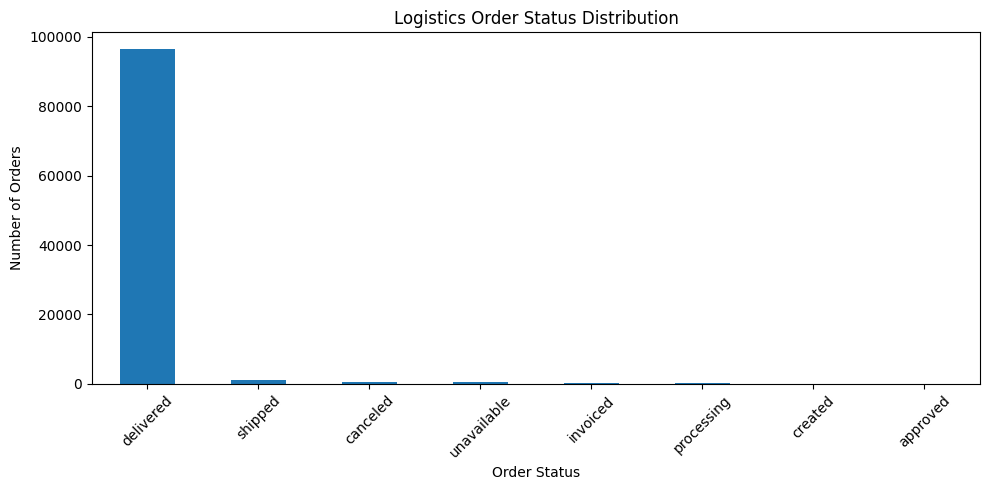

In [21]:

import matplotlib.pyplot as plt

status_counts = df_clean['order_status'].value_counts()

plt.figure(figsize=(10, 5))
status_counts.plot(kind='bar')

plt.title('Logistics Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


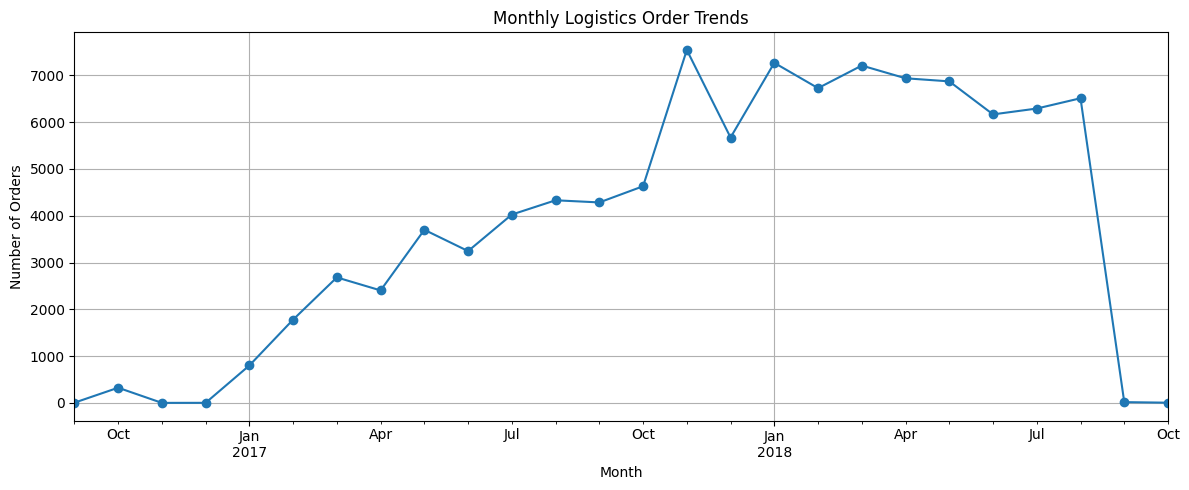

In [22]:

monthly_orders = (
    df_clean.set_index('order_purchase_timestamp')
    .resample('ME')
    .size()
)

plt.figure(figsize=(12, 5))
monthly_orders.plot(kind='line', marker='o')

plt.title('Monthly Logistics Order Trends')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.grid(True)
plt.tight_layout()
plt.show()


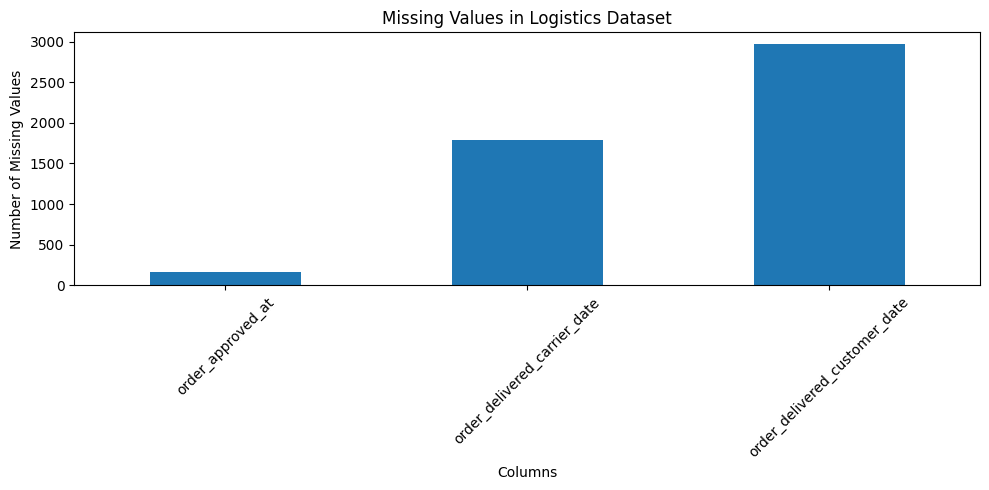

In [23]:

missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0]

plt.figure(figsize=(10, 5))
missing_data.plot(kind='bar')

plt.title('Missing Values in Logistics Dataset')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('missing_values_analysis.png', dpi=300)
plt.show()


In [24]:
plt.savefig('graph_name.png', dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [25]:
plt.savefig('/content/missing_values_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

<Figure size 640x480 with 0 Axes>